In [56]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

In [57]:
df_background=pd.read_csv('/home/um40/LB2_project_Group_1/Data_analysis/aa_composition_swissprot.tsv',sep='\t')
df_background['Percent']=(df_background['Percent']
                        .str.replace('%', '', regex=False)
                        .astype(float))


df_background['Percent']/=100
df_background.rename(columns={'Percent':'freq_back','1-letter code':'aa'},inplace=True)

In [58]:
from collections import Counter

file_path='/home/um40/LB2_project_Group_1/Data_preparation/Data_cleaning/positive_set.cluster/cluster-results-positive_rep_seq.fasta'
keys = "ACDEFGHIKLMNPQRSTVWY" 
dict_aa= Counter({aa: 0 for aa in keys})

with open(file_path) as file:
    for line in file:
        line=line.strip()
        if line.startswith('>') or not line:
            continue 
        for aa in line:
            aa=aa.upper()
            if aa in dict_aa:
                dict_aa[aa]+=1
        

# for k,v in dict_aa.items():
#     print(f'{k}:{v}')

In [59]:
df_pos = pd.DataFrame({'aa': dict_aa.keys(), 'Count': dict_aa.values()})
df_pos['freq_pos']=df_pos['Count']/sum(dict_aa.values())


df = pd.merge(df_pos[['aa', 'freq_pos']], df_background[['aa', 'freq_back']], on='aa')


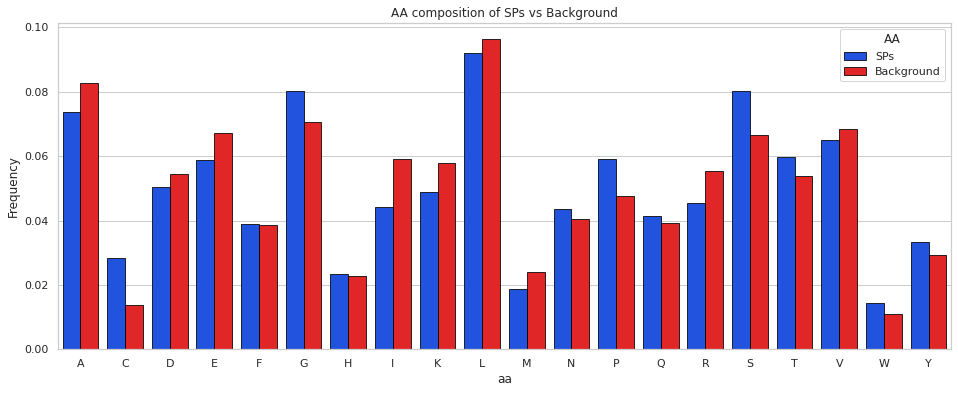

In [68]:
palette = {'SPs': "#0144fe", 'Background': "#ff0707"}
sns.set_theme(style="whitegrid")

df_melted= df.melt(id_vars='aa', value_vars=['freq_pos', 'freq_back'], var_name='AA', value_name='Frequency')
df_melted['AA'] = df_melted['AA'].map({'freq_pos': 'SPs', 'freq_back': 'Background'})

plt.figure(figsize=(16, 6))


sns.barplot(data=df_melted, x='aa', y='Frequency', hue='AA',palette=palette,
    edgecolor='black',
    linewidth=0.8)

plt.title('AA composition of SPs vs Background')
plt.xlabel='Residue Type'
plt.ylabel='Frequency'

